# 实验报告02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

姓名：高琴　学号：20244080227

运行环境：独立 conda 环境 `homework`（Python 3.12，NumPy / SciPy / Matplotlib / pandas）。

In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

STUDENT_ID = 20244080227

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]     {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] homework
[学号]     20244080227
[机器指纹] 599de81f2de1f686
[RUN_ID]   20244080227-599de81f2de1f686


In [2]:
import matplotlib.pyplot as plt
from scipy import linalg, optimize, stats

plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei", "Noto Sans CJK SC", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("numpy", np.__version__)
print("scipy", scipy.__version__)
print("matplotlib", matplotlib.__version__)
print("pandas", pd.__version__)

numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
pandas 3.0.6


## 实验1：NumPy 数组、数据类型与索引

### 1.1 三种 dtype

In [3]:
a_int = np.array([1, 2, 3, 4])
a_float = np.array([[1.5, 2.0], [3.25, 4.0]])
a_bool = np.array([True, False, True])
for name, arr in [("整数", a_int), ("浮点数", a_float), ("布尔", a_bool)]:
    print(f"{name}: dtype={arr.dtype}, shape={arr.shape}, ndim={arr.ndim}")

mixed = np.array([1, 2.5, 3])
print(mixed, mixed.dtype)
print([1, "a", 2.5])

整数: dtype=int64, shape=(4,), ndim=1
浮点数: dtype=float64, shape=(2, 2), ndim=2
布尔: dtype=bool, shape=(3,), ndim=1
[1.  2.5 3. ] float64
[1, 'a', 2.5]


ndarray 里所有元素是同一种类型，比如 `[1, 2.5, 3]` 放进数组后整数也被转成了 float64；
Python 列表里每个元素可以是不同类型（上面的列表同时有整数、字符串、浮点数）。
类型统一后数组可以连续存放、整体计算，所以比列表快。

### 1.2 reshape

In [4]:
x = np.arange(12)
print(x)
x34 = x.reshape(3, 4)
print(x34)
x232 = x.reshape(2, 3, 2)
print(x232)
try:
    x.reshape(5, 3)
except ValueError as e:
    print("ValueError:", e)

[ 0  1  2  3  4  5  6  7  8  9 10 11]
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
ValueError: cannot reshape array of size 12 into shape (5,3)


改变形状前后元素总数不能变：3×4 和 2×3×2 都等于 12，所以可以；5×3=15 ≠ 12 就会报错。

### 1.3 索引

这里的“第 2 行”按习惯从 1 开始数，对应下标 1；“第 1 至第 3 列”对应下标 0 到 2。

In [5]:
row2 = x34[1]
cols = x34[:, 0:3]
big = x34[x34 > 6]
print("第 2 行:", row2, row2.shape)
print("第 1~3 列:")
print(cols, cols.shape)
print("大于 6:", big, big.shape)

第 2 行: [4 5 6 7] (4,)
第 1~3 列:
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] (3, 3)
大于 6: [ 7  8  9 10 11] (5,)


取一行得到一维数组；切片保持二维；布尔索引会把选中的元素拉平成一维。

### 1.4 组合条件

In [6]:
y = np.arange(10)
print(y[(y < 2) | (y > 7)])
print(y[np.logical_or(y < 2, y > 7)])
print(y[(y > 3) & (y < 7)])
print(y[np.logical_and(y > 3, y < 7)])

[0 1 8 9]
[0 1 8 9]
[4 5 6]
[4 5 6]


`|`、`&` 的优先级比 `<`、`>` 高，每个比较都要加括号，不然会报错或结果不对。

### 1.5 逐元素乘法与矩阵乘法

In [7]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print("A * B\n", A * B)
print("np.multiply\n", np.multiply(A, B))
print("A @ B\n", A @ B)
print("np.matmul\n", np.matmul(A, B))

A * B
 [[ 5 12]
 [21 32]]
np.multiply
 [[ 5 12]
 [21 32]]
A @ B
 [[19 22]
 [43 50]]
np.matmul
 [[19 22]
 [43 50]]


`*` 和 `np.multiply` 是对应位置相乘，例如左上角 1×5=5；
`@` 和 `np.matmul` 是矩阵乘法，左上角是 A 第一行乘 B 第一列：1×5 + 2×7 = 19。

## 实验2：随机抽样、统计与缺失值

随机数统一用 `np.random.default_rng(2024)` 生成，每次运行结果一样。

In [8]:
rng = np.random.default_rng(2024)
scores = np.clip(rng.normal(70, 10, 1000), 0, 100)
print("样本数", scores.size)
print("最小值", round(scores.min(), 2))
print("最大值", round(scores.max(), 2))
print("均值", round(scores.mean(), 2))
print("标准差", round(scores.std(), 2))
print("极差", round(np.ptp(scores), 2))

样本数 1000
最小值 36.51
最大值 100.0
均值 70.14
标准差 10.15
极差 63.49


均值和标准差接近设定的 70 和 10。最大值正好是 100，说明有超过 100 的值被 `clip` 截断了。

### 2.2 不放回抽样

In [9]:
nums = np.arange(1, 11)
p = nums / nums.sum()
print("权重", np.round(p, 3))
print("均匀抽样", rng.choice(nums, size=5, replace=False))
print("加权抽样", rng.choice(nums, size=5, replace=False, p=p))

uniform_cnt = np.zeros(10)
weighted_cnt = np.zeros(10)
for _ in range(2000):
    uniform_cnt[rng.choice(nums, 5, replace=False) - 1] += 1
    weighted_cnt[rng.choice(nums, 5, replace=False, p=p) - 1] += 1
print(pd.DataFrame({"均匀": uniform_cnt, "加权": weighted_cnt}, index=nums).T.astype(int))

权重 [0.018 0.036 0.055 0.073 0.091 0.109 0.127 0.145 0.164 0.182]
均匀抽样 [10  9  1  6  7]
加权抽样 [4 5 7 8 6]
     1     2     3     4     5     6     7     8     9     10
均匀  975  1009  1009  1030  1030  1005  1009  1015   973   945
加权  239   456   653   876  1010  1149  1284  1362  1454  1517


两种写法的区别只在 `p` 参数。重复 2000 次统计每个数被抽中的次数：均匀抽样每个数都在 1000 次左右；
加权抽样大的数被抽中更多，10 几乎每次都在，1 很少出现。

### 2.3 permutation 和 shuffle

In [10]:
arr = np.arange(1, 11)
print("原数组", arr)
new = rng.permutation(arr)
print("permutation 返回", new)
print("原数组", arr)
rng.shuffle(arr)
print("shuffle 之后原数组", arr)

原数组 [ 1  2  3  4  5  6  7  8  9 10]
permutation 返回 [ 9  7 10  8  6  1  4  5  3  2]
原数组 [ 1  2  3  4  5  6  7  8  9 10]
shuffle 之后原数组 [ 7  4  8  9  6  5  3 10  2  1]


`permutation` 返回打乱后的新数组，原数组不动；`shuffle` 直接改原数组，没有返回值。

### 2.4 缺失值

第 10、20、30 个值对应下标 9、19、29。

In [11]:
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan
print("缺失值个数", np.isnan(scores_nan).sum())
print("np.mean", np.mean(scores_nan))
print("np.nanmean", round(np.nanmean(scores_nan), 2))
print("np.max", np.max(scores_nan), " np.nanmax", round(np.nanmax(scores_nan), 2))

缺失值个数 3
np.mean nan
np.nanmean 70.14
np.max nan  np.nanmax 100.0


只要有一个 nan，`mean`、`max`、`sum` 这些普通函数的结果就都是 nan；
要用 `nanmean`、`nanmax` 之类的函数跳过缺失值，才能得到 997 个有效成绩的统计结果。

### 2.5 整理成表格（只放在内存里）

In [12]:
score_table = pd.DataFrame({"序号": np.arange(1, scores_nan.size + 1), "成绩": scores_nan})
print(score_table.shape)
print(score_table.head(12))
print(score_table[score_table["成绩"].isna()])

(1000, 2)
    序号         成绩
0    1  80.288569
1    2  86.419200
2    3  81.467195
3    4  60.268205
4    5  56.071999
5    6  70.671964
6    7  78.613509
7    8  75.091868
8    9  88.102856
9   10        NaN
10  11  76.397596
11  12  62.686775
    序号  成绩
9   10 NaN
19  20 NaN
29  30 NaN


## 实验3：SciPy 数值计算与 Matplotlib 可视化

### 3.1 解线性方程组

In [13]:
M = np.array([[3, 1], [1, 2]])
rhs = np.array([9, 8])
sol = linalg.solve(M, rhs)
print("x, y =", sol)
print("代入:", M @ sol)
print(np.allclose(M @ sol, rhs))

x, y = [2. 3.]
代入: [9. 8.]
True


解是 x=2，y=3。代回去 3×2+3=9，2+2×3=8，和右边一致。

### 3.2 求根

In [14]:
f = lambda x: x ** 2 - 2
for x0 in [1, -1]:
    r = optimize.root(f, x0)
    print(f"初始值 {x0}: success={r.success}, 根={r.x[0]:.10f}, f(根)={f(r.x[0]):.2e}")
print("sqrt(2) =", np.sqrt(2))

初始值 1: success=True, 根=1.4142135624, f(根)=-8.88e-16
初始值 -1: success=True, 根=-1.4142135624, f(根)=-8.88e-16
sqrt(2) = 1.4142135623730951


初始值取 1 收敛到正根 1.4142…，取 -1 收敛到负根，函数值都在 1e-12 量级，可以当作 0。

### 3.3 求最小值

In [15]:
g = lambda x: x ** 2 + x + 2
res = optimize.minimize(g, x0=0)
print("极小点", res.x[0])
print("最小值", res.fun)
print("解析解", -0.5, g(-0.5))

极小点 -0.5000000064345924
最小值 1.75
解析解 -0.5 1.75


求导 2x+1=0 得 x=-0.5，最小值 0.25-0.5+2=1.75，数值结果和解析结果一致。

### 3.4 独立样本 t 检验

In [16]:
rng_t = np.random.default_rng(7)
g1 = rng_t.normal(0, 1, 100)
g2 = rng_t.normal(1, 1, 100)
print("两组均值", round(g1.mean(), 3), round(g2.mean(), 3))
t, pval = stats.ttest_ind(g1, g2)
print("t =", round(t, 4))
print("p =", pval)
print("拒绝原假设" if pval < 0.05 else "不拒绝原假设")

两组均值 -0.173 0.909
t = -8.736
p = 1.0189084750523142e-15
拒绝原假设


p 值远小于 0.05，拒绝“两组均值相等”的原假设，认为两组均值有显著差异。这和数据的生成方式一致（真实均值差 1）。

### 3.5 作图

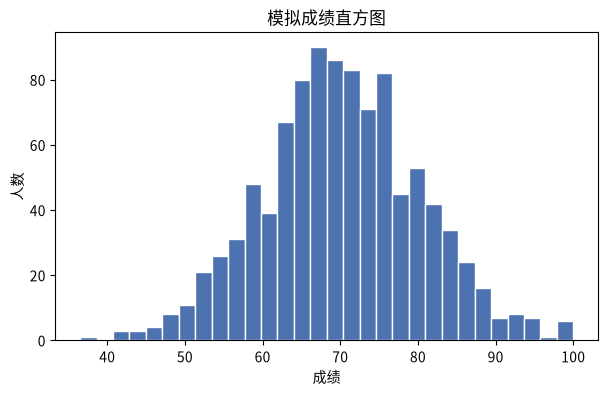

In [17]:
valid = score_table["成绩"].dropna()

plt.figure(figsize=(7, 4))
plt.hist(valid, bins=30, color="#4C72B0", edgecolor="white")
plt.title("模拟成绩直方图")
plt.xlabel("成绩")
plt.ylabel("人数")
plt.show()

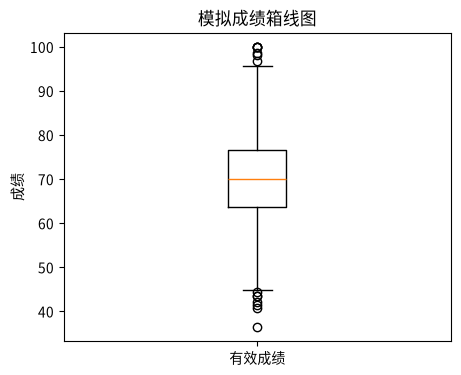

In [18]:
plt.figure(figsize=(5, 4))
plt.boxplot(valid)
plt.title("模拟成绩箱线图")
plt.xticks([1], ["有效成绩"])
plt.ylabel("成绩")
plt.show()

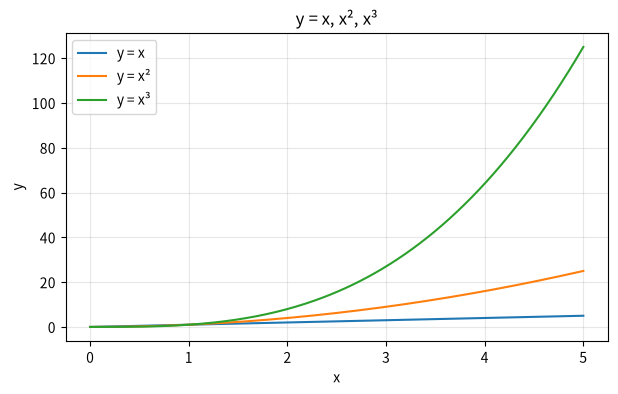

In [19]:
xs = np.linspace(0, 5, 200)
plt.figure(figsize=(7, 4))
plt.plot(xs, xs, label="y = x")
plt.plot(xs, xs ** 2, label="y = x²")
plt.plot(xs, xs ** 3, label="y = x³")
plt.title("y = x, x², x³")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

直方图大致是以 70 为中心的钟形，100 处因为截断有一点堆积。箱线图里两端的圆点是离群值。
折线图中 x<1 时三条线差别很小，x>1 后 x³ 增长最快，到 x=5 时达到 125。

## 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

### 4.1 创建 DataFrame

In [20]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}
df = pd.DataFrame(records).set_index("Name")
subjects = ["Math", "English", "Python"]
df["Total"] = df[subjects].sum(axis=1)
df["Average"] = df[subjects].mean(axis=1).round(2)
print(df.index)
print(df.columns)
print(df.head(3))
print(df.describe().round(2))

Index(['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank'], dtype='str', name='Name')
Index(['Group', 'Math', 'English', 'Python', 'Total', 'Average'], dtype='str')
      Group  Math  English  Python  Total  Average
Name                                              
Alice     A    88       90      95    273    91.00
Bob       A    72       68      80    220    73.33
Carol     B    91       85      89    265    88.33
        Math  English  Python   Total  Average
count   6.00     6.00    6.00    6.00     6.00
mean   79.83    80.83   83.67  244.33    81.44
std     9.91     9.66    8.55   25.78     8.60
min    65.00    68.00   70.00  208.00    69.33
25%    73.75    74.00   80.50  225.75    75.25
50%    81.50    81.00   84.00  250.00    83.34
75%    87.00    88.75   88.25  263.00    87.66
max    91.00    92.00   95.00  273.00    91.00


### 4.2 loc / iloc 与条件筛选

In [21]:
print(df.loc["Carol"])
print(df.iloc[2])
print(df[df["Average"] >= 80])

Group          B
Math          91
English       85
Python        89
Total        265
Average    88.33
Name: Carol, dtype: object
Group          B
Math          91
English       85
Python        89
Total        265
Average    88.33
Name: Carol, dtype: object
      Group  Math  English  Python  Total  Average
Name                                              
Alice     A    88       90      95    273    91.00
Carol     B    91       85      89    265    88.33
Eva       A    79       92      86    257    85.67
Frank     B    84       77      82    243    81.00


`loc` 按行标签取，`iloc` 按位置取，Carol 是第 3 行，所以下标是 2。平均分不低于 80 的有 Alice、Carol、Eva、Frank 四人。

### 4.3 按列、按行求均值

In [22]:
print(df[subjects].mean(axis=0).round(2))
print(df[subjects].mean(axis=1).round(2))

Math       79.83
English    80.83
Python     83.67
dtype: float64
Name
Alice    91.00
Bob      73.33
Carol    88.33
David    69.33
Eva      85.67
Frank    81.00
dtype: float64


`axis=0` 沿着行的方向压缩，得到每科的均值；`axis=1` 沿着列的方向压缩，得到每个人的均值。

### 4.4 apply、agg、rank

In [23]:
df["Best"] = df[subjects].apply(max, axis=1)
print(df[subjects + ["Best"]])
print(df[subjects].agg(["min", "mean", "max"]).round(2))
df["MathRank"] = df["Math"].rank(ascending=False).astype(int)
print(df[["Math", "MathRank"]].sort_values("MathRank"))

       Math  English  Python  Best
Name                              
Alice    88       90      95    95
Bob      72       68      80    80
Carol    91       85      89    91
David    65       73      70    73
Eva      79       92      86    92
Frank    84       77      82    84
       Math  English  Python
min   65.00    68.00   70.00
mean  79.83    80.83   83.67
max   91.00    92.00   95.00
       Math  MathRank
Name                 
Carol    91         1
Alice    88         2
Frank    84         3
Eva      79         4
Bob      72         5
David    65         6


### 4.5 groupby 与 transform

In [24]:
grouped = df.groupby("Group")
summary = grouped[subjects].mean().round(2)
summary.insert(0, "人数", grouped.size())
print(summary)
df["GroupPythonMean"] = grouped["Python"].transform("mean").round(2)
print(df[["Group", "Python", "GroupPythonMean"]])

       人数   Math  English  Python
Group                            
A       3  79.67    83.33   87.00
B       3  80.00    78.33   80.33
      Group  Python  GroupPythonMean
Name                                
Alice     A      95            87.00
Bob       A      80            87.00
Carol     B      89            80.33
David     B      70            80.33
Eva       A      86            87.00
Frank     B      82            80.33


`agg`/`mean` 每组只返回一行，`transform` 返回的结果和原表一样长，所以能直接作为新列加回去。

### 4.6 filter

In [25]:
kept = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print("保留的组:", kept["Group"].unique().tolist())
print(kept[["Group", "Python"]])

保留的组: ['A', 'B']
      Group  Python
Name               
Alice     A      95
Bob       A      80
Carol     B      89
David     B      70
Eva       A      86
Frank     B      82


A 组 Python 平均分 87，B 组 80.33，都不低于 80，所以两组都保留了，6 名学生都在。

### 4.7 协方差与相关系数

In [26]:
print(df[subjects].cov().round(2))
print(df[subjects].corr().round(4))

          Math  English  Python
Math     98.17    62.57   74.93
English  62.57    93.37   62.53
Python   74.93    62.53   73.07
           Math  English  Python
Math     1.0000   0.6535  0.8848
English  0.6535   1.0000  0.7571
Python   0.8848   0.7571  1.0000


以 Math 和 Python 为例：协方差 74.93 是正数，说明数学分高的学生 Python 分通常也高，二者同方向变化；
但协方差的大小受分数单位和波动幅度影响，不好直接比较强弱。
相关系数把它标准化到 -1 到 1 之间，Math 和 Python 是 0.88，是三对里最大的，线性关系最强；Math 和 English 只有 0.65，相对弱一些。
样本只有 6 个人，这个结论只能说明这组数据。

### 4.8 内存中的 CSV 读写

用 `io.StringIO` 代替文件，写出再读回来，不在磁盘上生成文件。实验2整理的成绩表也一起写读一次。

In [27]:
import io

buf = io.StringIO()
df.to_csv(buf)
text = buf.getvalue()
print(text[:200])
df_back = pd.read_csv(io.StringIO(text), index_col="Name")
print(df_back.equals(df))

buf2 = io.StringIO()
score_table.to_csv(buf2, index=False)
score_back = pd.read_csv(io.StringIO(buf2.getvalue()))
print(score_back.shape, score_back["成绩"].isna().sum())

Name,Group,Math,English,Python,Total,Average,Best,MathRank,GroupPythonMean
Alice,A,88,90,95,273,91.0,95,2,87.0
Bob,A,72,68,80,220,73.33,80,5,87.0
Carol,B,91,85,89,265,88.33,91,1,80.33
David,B,65,73,70
True
(1000, 2) 3


读回的表和原表完全相同；成绩表读回后仍是 1000 行，3 个缺失值也保留了下来（CSV 中写成空字段）。